<a href="https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/master/notebooks/process/doe_big_hill_connected_vacuum_sensitivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DOE Big Hill atmospheric-to-vacuum sensitivity with NeqSim

**Version 1.0.0 — executed against NeqSim master commit `74a0529d19db577cb41034685905067a8ac9d0c6`.**

This notebook carries one public U.S. Strategic Petroleum Reserve Big Hill Sweet assay through a fired heater, a rigorous atmospheric column, and the connected vacuum reboiler-temperature sensitivity introduced by [NeqSim PR #4501](https://github.com/equinor/neqsim/pull/4501).

## Learning outcomes

1. Load current NeqSim source through JPype with commit, JAR-hash, and class-origin evidence.
2. Preserve one modeled assay identity across heating, atmospheric fractionation, and vacuum screening.
3. Evaluate a narrow 698–702 K vacuum reboiler-temperature perturbation while holding the other column inputs fixed.
4. Audit total mass, component molar flow, energy, MESH residual, product ordering, and source-stream immutability.
5. Distinguish numerical screening evidence from plant data, ASTM qualification, operating guidance, or design approval.


## Engineering boundary and public provenance

The material identity is the public DOE SPR Big Hill Sweet assay represented by NeqSim's `DoeBigHillSweetAssay`. The source workbooks are:

- [DOE SPR Big Hill Sweet comprehensive assay](https://www.spr.doe.gov/reports/Assays/2024/BigHillSwAssay.xlsx)
- [DOE SPR Big Hill Sweet PIANO assay](https://www.spr.doe.gov/reports/Assays/2021/BigHillSwPIANO.xlsx)

The calculation uses the repository's transparent pseudo-component representation; it introduces no copied proprietary coefficients or plant operating data. Atmospheric and vacuum operating settings are explicit engineering assumptions.

For each vacuum point, the qualified result checks

$$\dot m_\mathrm{feed}=\dot m_\mathrm{overhead}+\dot m_\mathrm{bottoms}$$

and the component form

$$\dot n_{i,\mathrm{feed}}=\dot n_{i,\mathrm{overhead}}+\dot n_{i,\mathrm{bottoms}}$$

within the documented 5% screening tolerance. These are numerical acceptance checks, not a matched vacuum-plant yield benchmark.


## 1. Clean runtime and current-source provenance

The first code cell provides a clean Colab installation route. The next cell resolves the exact `equinor/neqsim` source revision, builds its runtime JAR when needed, records the SHA-256 identity, disables wrapper autostart, adds the source JAR to JPype, and proves that the main-only connected sensitivity class came from that JAR.


In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys


NEQSIM_PYTHON_VERSION = "3.26.0"
required_modules = ("jpype", "matplotlib", "numpy", "pandas")
missing_modules = [
    name
    for name in required_modules
    if importlib.util.find_spec(name) is None
]
if missing_modules:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--no-cache-dir",
            f"neqsim=={NEQSIM_PYTHON_VERSION}",
            "matplotlib",
            "numpy",
            "pandas",
        ],
        check=True,
    )

print(f"NeqSim Python bridge: {importlib.metadata.version('neqsim')}")
print(f"Python: {sys.version.split()[0]}")


NeqSim Python bridge: 3.26.0
Python: 3.12.14


In [2]:
import hashlib
import os
import platform
import subprocess
from pathlib import Path
from urllib.parse import unquote, urlparse


NEQSIM_SOURCE_REF = "74a0529d19db577cb41034685905067a8ac9d0c6"
NEQSIM_SOURCE_REPOSITORY = "https://github.com/equinor/neqsim.git"
os.environ["NEQSIM_JVM_AUTOSTART"] = "0"

source_root_text = os.environ.get("NEQSIM_SOURCE_ROOT", "")
if source_root_text:
    source_root = Path(source_root_text).resolve()
else:
    source_root = Path("neqsim-current-source").resolve()
    if not source_root.exists():
        subprocess.run(
            ["git", "clone", NEQSIM_SOURCE_REPOSITORY, str(source_root)],
            check=True,
        )
    subprocess.run(
        ["git", "fetch", "origin", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
    )
    subprocess.run(
        ["git", "checkout", "--detach", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
    )

resolved_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=source_root,
    text=True,
).strip()
assert resolved_commit == NEQSIM_SOURCE_REF

source_jar_text = os.environ.get("NEQSIM_SOURCE_JAR", "")
if source_jar_text:
    source_jar = Path(source_jar_text).resolve()
else:
    subprocess.run(
        [
            "./mvnw",
            "-q",
            "-DskipTests",
            "-Dmaven.javadoc.skip=true",
            "package",
        ],
        cwd=source_root,
        check=True,
    )
    jar_candidates = [
        path
        for path in (source_root / "target").glob("neqsim-*.jar")
        if all(token not in path.name for token in ("shaded", "sources", "javadoc"))
    ]
    if not jar_candidates:
        raise FileNotFoundError("The NeqSim source build produced no runtime JAR.")
    source_jar = max(jar_candidates, key=lambda path: path.stat().st_size).resolve()

source_jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()
print(f"NeqSim repository: {NEQSIM_SOURCE_REPOSITORY}")
print(f"NeqSim source commit: {resolved_commit}")
print(f"NeqSim source JAR SHA-256: {source_jar_sha256}")
print(f"Java: {platform.java_ver()[0] or 'reported below by JPype'}")


NeqSim repository: https://github.com/equinor/neqsim.git
NeqSim source commit: 74a0529d19db577cb41034685905067a8ac9d0c6
NeqSim source JAR SHA-256: da6d66a14de7410b596308358664df4b50f20091799e4d48aad0686561f44270
Java: reported below by JPype


In [3]:
import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from jpype import JArray, JClass, JDouble


jpype.addClassPath(str(source_jar))
if not jpype.isJVMStarted():
    jpype.startJVM()

SystemSrkEos = JClass("neqsim.thermo.system.SystemSrkEos")
DoeBigHillSweetAssay = JClass(
    "neqsim.thermo.characterization.DoeBigHillSweetAssay"
)
Stream = JClass("neqsim.process.equipment.stream.Stream")
FiredHeater = JClass("neqsim.process.equipment.heatexchanger.FiredHeater")
DistillationColumn = JClass(
    "neqsim.process.equipment.distillation.DistillationColumn"
)
Sensitivity = JClass(
    "neqsim.process.equipment.distillation."
    "DoeBigHillVacuumReboilerTemperatureSensitivity"
)
OperatingInputs = JClass(
    "neqsim.process.equipment.distillation."
    "DoeBigHillVacuumFractionationCase$OperatingInputs"
)
UUID = JClass("java.util.UUID")
System = JClass("java.lang.System")

code_source_uri = str(
    Sensitivity.class_
    .getProtectionDomain()
    .getCodeSource()
    .getLocation()
    .toURI()
)
loaded_path = Path(unquote(urlparse(code_source_uri).path)).resolve()
assert loaded_path == source_jar

print(f"Loaded class: {Sensitivity.class_.getName()}")
print(f"Class code source: {loaded_path.name}")
print(f"Java runtime: {System.getProperty('java.runtime.version')}")


Loaded class: neqsim.process.equipment.distillation.DoeBigHillVacuumReboilerTemperatureSensitivity
Class code source: neqsim-3.26.0.jar
Java runtime: 17.0.20+8-1-24.04-Ubuntu


## 2. Construct the connected atmospheric workflow

The thermodynamic model is SRK with the classic mixing rule. The complete public DOE modeled assay is applied before setting the 5,000 kg/h feed state. The fired-heater fuel, efficiency, emissions, and stack settings are transparent screening assumptions.

The eight-simple-tray atmospheric column is the merged campaign qualification case: partial condenser, one 10% liquid side draw at tray 4, explicit 1.2–1.5 bara pressure profile, 650 K reboiler outlet, and the MESH-residual solver. The model is composable because the solved atmospheric liquid-bottoms stream is passed directly to the vacuum API.


In [4]:
run_id = UUID.randomUUID()
crude = SystemSrkEos(298.15, 1.5)
assay = DoeBigHillSweetAssay.create(crude)
assay.apply()
crude.setMixingRule("classic")

feed = Stream("DOE Big Hill crude inlet", crude)
feed.setFlowRate(5000.0, "kg/hr")
feed.setTemperature(298.15, "K")
feed.setPressure(1.5, "bara")
feed.run(run_id)

furnace = FiredHeater("DOE Big Hill crude furnace", feed)
furnace.setOutletTemperature(550.0, "K")
furnace.setOutletPressure(1.5, "bara")
furnace.setThermalEfficiency(0.85)
furnace.setFuelLHV(48.0e6)
furnace.setFuelCO2Factor(2.75)
furnace.setNoxFactor(0.08)
furnace.setStackTemperature(423.15)
furnace.run(run_id)

atmospheric = DistillationColumn(
    "DOE Big Hill connected atmospheric",
    8,
    True,
    True,
)
atmospheric.addFeedStream(furnace.getOutletStream(), 4)
atmospheric.setTopPressure(1.2)
atmospheric.setBottomPressure(1.5)
atmospheric.setCondenserMode(DistillationColumn.CondenserMode.PARTIAL)
atmospheric.getReboiler().setOutletTemperature(650.0)
atmospheric.setCondenserRefluxRatio(1.0)
atmospheric.setLiquidSideDrawFraction(4, 0.10)
atmospheric.setSolverType(DistillationColumn.SolverType.MESH_RESIDUAL)
atmospheric.setMaxNumberOfIterations(300)
atmospheric.setTemperatureTolerance(0.20)
atmospheric.setMassBalanceTolerance(5.0e-2)
atmospheric.setEnthalpyBalanceTolerance(5.0e-2)
atmospheric.setEnforceEnergyBalanceTolerance(True)
atmospheric.run(run_id)

atmospheric_bottoms = atmospheric.getLiquidOutStream()
source_mass_flow = atmospheric_bottoms.getFlowRate("kg/hr")
source_composition = np.array(
    atmospheric_bottoms.getThermoSystem().getMolarComposition(),
    dtype=float,
)

front_end_table = pd.DataFrame(
    {
        "Metric": [
            "Feed mass flow",
            "Furnace absorbed duty",
            "Furnace fired duty",
            "Fuel demand",
            "Direct CO2",
            "Atmospheric bottoms",
            "Atmospheric mass-balance error",
            "Atmospheric energy-balance error",
        ],
        "Value": [
            feed.getFlowRate("kg/hr"),
            furnace.getAbsorbedDuty("kW"),
            furnace.getFiredDuty("kW"),
            furnace.getFuelConsumption("kg/hr"),
            furnace.getCO2Emissions("kg/hr"),
            source_mass_flow,
            atmospheric.getMassBalanceError(),
            atmospheric.getEnergyBalanceError(),
        ],
        "Unit": [
            "kg/h",
            "kW",
            "kW",
            "kg/h",
            "kg/h",
            "kg/h",
            "relative",
            "relative",
        ],
    }
)
display(front_end_table.round({"Value": 8}))


,Metric,Value,Unit
0,Feed mass flow,5000.000000,kg/h
1,Furnace absorbed duty,1037.365573,kW
2,Furnace fired duty,1220.430086,kW
3,Fuel demand,91.532256,kg/h
4,Direct CO2,251.713705,kg/h
5,Atmospheric bottoms,2034.516494,kg/h
6,Atmospheric mass-balance error,0.000000,relative
7,Atmospheric energy-balance error,0.000000,relative


## 3. Run the connected vacuum sensitivity

Only the reboiler outlet temperature changes between points: 698, 700, and 702 K. The vacuum feed state (640 K, 0.12 bara), top and bottom pressures (0.08 and 0.16 bara), 12 simple trays, feed tray 4, and condenser reflux ratio 0.5 remain fixed.

The API independently clones, constructs, solves, and evaluates each point from the same atmospheric-bottoms source. The 4 K span is deliberately narrow enough to test local numerical behavior; it is not a recommended operating envelope.


In [5]:
baseline_inputs = OperatingInputs(
    12,
    4,
    640.0,
    0.12,
    0.08,
    0.16,
    700.0,
    0.5,
)
reboiler_temperatures = JArray(JDouble)([698.0, 700.0, 702.0])
sensitivity = Sensitivity.run(
    "DOE Big Hill connected vacuum screen",
    atmospheric_bottoms,
    baseline_inputs,
    reboiler_temperatures,
)

records = []
for point in sensitivity.getPoints():
    result = point.getFractionationResult()
    overhead = result.getProduct("Overhead")
    residue = result.getProduct("Bottoms")
    records.append(
        {
            "Reboiler [K]": point.getReboilerTemperatureKelvin(),
            "Overhead fraction [%]": 100.0 * point.getOverheadMassFraction(),
            "Overhead [kg/h]": overhead.getMassFlowKgPerHour(),
            "Residue [kg/h]": residue.getMassFlowKgPerHour(),
            "Overhead mean NBP [C]": overhead.getMeanNormalBoilingPointCelsius(),
            "Residue mean NBP [C]": residue.getMeanNormalBoilingPointCelsius(),
            "Overhead T10 [C]": overhead.getNormalBoilingPointQuantileCelsius(0.10),
            "Overhead T90 [C]": overhead.getNormalBoilingPointQuantileCelsius(0.90),
            "Residue T10 [C]": residue.getNormalBoilingPointQuantileCelsius(0.10),
            "Residue T90 [C]": residue.getNormalBoilingPointQuantileCelsius(0.90),
            "Mass closure": result.getMassClosureRelativeError(),
            "Component closure": (
                result.getMaximumComponentMolarClosureRelativeError()
            ),
            "Energy error": result.getColumnEnergyBalanceError(),
            "MESH residual": result.getMeshResidualNorm(),
            "Iterations": result.getIterationCount(),
            "Solve time [s]": result.getSolveTimeSeconds(),
        }
    )

results = pd.DataFrame(records)
display(results.round(6))


,Reboiler [K],Overhead fraction [%],Overhead [kg/h],Residue [kg/h],Overhead mean NBP [C],Residue mean NBP [C],Overhead T10 [C],Overhead T90 [C],Residue T10 [C],Residue T90 [C],Mass closure,Component closure,Energy error,MESH residual,Iterations,Solve time [s]
0,698.0,71.953165,1463.899015,570.617479,397.681624,547.141692,312.920218,461.261136,461.261136,558.485579,0.0,0.0,0.024807,0.012252,600,49.137743
1,700.0,72.234274,1469.618213,564.898281,397.873152,548.274295,312.920218,461.261136,461.261136,558.485579,0.0,0.0,0.024631,0.012165,600,47.390252
2,702.0,72.496050,1474.944101,559.572393,398.050509,549.356008,312.920218,461.261136,558.485579,558.485579,0.0,0.0,0.024457,0.012081,600,51.758020


The pseudo-component T10/T90 values are discrete normal-boiling-point diagnostics. They are not ASTM D86, ASTM D1160, TBP, or simulated-distillation temperatures.


In [6]:
post_mass_flow = atmospheric_bottoms.getFlowRate("kg/hr")
post_composition = np.array(
    atmospheric_bottoms.getThermoSystem().getMolarComposition(),
    dtype=float,
)
source_mass_delta = abs(post_mass_flow - source_mass_flow)
source_composition_delta = np.max(
    np.abs(post_composition - source_composition)
)

overhead_fractions = results["Overhead fraction [%]"].to_numpy()
overhead_means = results["Overhead mean NBP [C]"].to_numpy()
residue_means = results["Residue mean NBP [C]"].to_numpy()

checks = {
    "Atmospheric MESH solve accepted": bool(atmospheric.solved()),
    "Atmospheric mass error <= 5%": atmospheric.getMassBalanceError() <= 0.05,
    "Atmospheric energy error <= 5%": atmospheric.getEnergyBalanceError() <= 0.05,
    "Source mass unchanged": source_mass_delta == 0.0,
    "Source composition unchanged": source_composition_delta == 0.0,
    "Vacuum mass closure <= 5%": (
        sensitivity.getMaximumMassClosureRelativeError() <= 0.05
    ),
    "Vacuum component closure <= 5%": (
        sensitivity.getMaximumComponentMolarClosureRelativeError() <= 0.05
    ),
    "Vacuum energy error <= 5%": (
        sensitivity.getMaximumColumnEnergyBalanceError() <= 0.05
    ),
    "Vacuum MESH residual <= 5%": (
        sensitivity.getMaximumMeshResidualNorm() <= 0.05
    ),
    "Overhead yield rises across screen": bool(
        np.all(np.diff(overhead_fractions) > 0.0)
    ),
    "Overhead remains lighter than residue": bool(
        np.all(overhead_means < residue_means)
    ),
}
assert all(checks.values())

validation_table = pd.DataFrame(
    {
        "Validation check": list(checks),
        "Passed": list(checks.values()),
    }
)
display(validation_table)
print(f"Source mass-flow delta: {source_mass_delta:.3e} kg/h")
print(f"Source maximum composition delta: {source_composition_delta:.3e}")
print(
    "Maximum vacuum mass/component closure errors: "
    f"{sensitivity.getMaximumMassClosureRelativeError():.3e} / "
    f"{sensitivity.getMaximumComponentMolarClosureRelativeError():.3e}"
)
print(
    "Maximum vacuum energy error / MESH residual: "
    f"{sensitivity.getMaximumColumnEnergyBalanceError():.5f} / "
    f"{sensitivity.getMaximumMeshResidualNorm():.5f}"
)


Source mass-flow delta: 0.000e+00 kg/h
Source maximum composition delta: 0.000e+00
Maximum vacuum mass/component closure errors: 2.728e-13 / 9.329e-13
Maximum vacuum energy error / MESH residual: 0.02481 / 0.01225


,Validation check,Passed
0,Atmospheric MESH solve accepted,True
1,Atmospheric mass error <= 5%,True
2,Atmospheric energy error <= 5%,True
3,Source mass unchanged,True
4,Source composition unchanged,True
5,Vacuum mass closure <= 5%,True
6,Vacuum component closure <= 5%,True
7,Vacuum energy error <= 5%,True
8,Vacuum MESH residual <= 5%,True
9,Overhead yield rises across screen,True


## 4. Sensitivity receipt and engineering interpretation

The first panel reports material redistribution. The second reports the mean pseudo-component normal boiling points of both vacuum products. Equal axis treatment is intentionally avoided because the yield and boiling diagnostics have different units and meanings.


Across the 698–702 K perturbation, overhead yield changes by 0.543 percentage points.


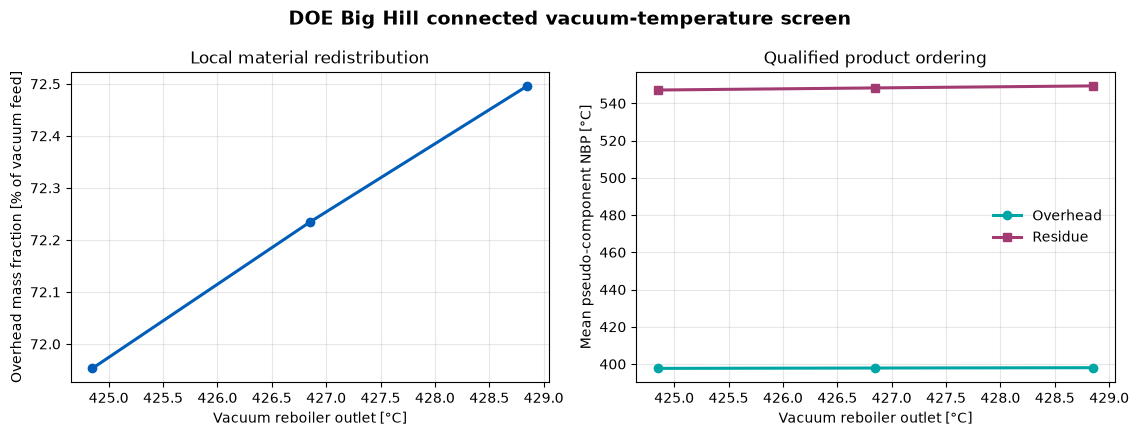

In [7]:
temperatures_c = results["Reboiler [K]"].to_numpy() - 273.15

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(
    temperatures_c,
    overhead_fractions,
    marker="o",
    color="#005EB8",
    linewidth=2.2,
)
axes[0].set_xlabel("Vacuum reboiler outlet [°C]")
axes[0].set_ylabel("Overhead mass fraction [% of vacuum feed]")
axes[0].set_title("Local material redistribution")
axes[0].grid(alpha=0.3)

axes[1].plot(
    temperatures_c,
    overhead_means,
    marker="o",
    color="#00A6A6",
    linewidth=2.2,
    label="Overhead",
)
axes[1].plot(
    temperatures_c,
    residue_means,
    marker="s",
    color="#A23B72",
    linewidth=2.2,
    label="Residue",
)
axes[1].set_xlabel("Vacuum reboiler outlet [°C]")
axes[1].set_ylabel("Mean pseudo-component NBP [°C]")
axes[1].set_title("Qualified product ordering")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.3)

figure.suptitle(
    "DOE Big Hill connected vacuum-temperature screen",
    fontsize=14,
    fontweight="bold",
)
figure.tight_layout()
plt.show()

yield_change = overhead_fractions[-1] - overhead_fractions[0]
print(
    "Across the 698–702 K perturbation, overhead yield changes by "
    f"{yield_change:.3f} percentage points."
)


## Results summary

- The 5,000 kg/h modeled DOE crude feed required about 1.04 MW absorbed furnace duty under the stated assumptions; the corresponding fired duty, fuel demand, and direct CO₂ receipt are retained above.
- The rigorous atmospheric column solved with mass and energy errors far below the 5% screening limit.
- The connected vacuum screen preserved the atmospheric-bottoms mass flow and complete molar composition exactly.
- Vacuum external mass and component closures remained near machine precision; energy error and MESH residual remained within the qualified column gates.
- Raising the assumed vacuum reboiler outlet from 698 to 702 K increased overhead yield by roughly 0.54 percentage points of vacuum feed. This three-point local trend is numerical evidence only.
- At every point, the overhead mean pseudo-component boiling point remained below the residue mean, preserving the qualified product ordering.

## Limitations and responsible use

- The DOE source identifies the crude assay, not the modeled atmospheric or vacuum operating conditions.
- Tray count, feed tray, temperatures, pressures, reflux, heater efficiency, fuel properties, and emissions factor are caller-owned assumptions.
- The model does not qualify tray efficiency, hydraulics, entrainment, pressure drop, pumparounds, stripping steam, fouling, coking, corrosion, metallurgy, control, relief, or safe operability.
- The three temperatures do not define a plant operating window, optimum, yield calibration, or uncertainty distribution.
- Product boiling diagnostics are discrete pseudo-component statistics, not ASTM D86/D1160/D2887 results.
- Design or operating decisions require reconciled plant data, an accepted assay, equipment constraints, uncertainty analysis, and accountable refinery/domain review.

## Validation evidence and next dependency

This executed notebook reaches the conservation/thermodynamic-consistency level of the evidence ladder and adds a defensible nearby-point trend. It does not claim independent plant-yield validation. The demonstrated Java API is regression-protected in [equinor/neqsim](https://github.com/equinor/neqsim); campaign scope and remaining gaps are tracked in [issue #3305](https://github.com/equinor/neqsim/issues/3305).

The next defensible step is not to widen this numerical perturbation. It is to add a public, license-clear atmospheric/vacuum benchmark or plant-independent literature comparison with matched inputs and documented uncertainty.
